# With Model V2-Exp14 Evaluation: MAE vs Model / Length / Noise

Standalone notebook. Generates fresh ANDI trajectories sweeping:
- **5 model types**: ATTM, CTRW, FBM, LW, SBM  
- **20 trajectory lengths**: T = 10, 20, …, 200  
- **4 noise levels**: σ = 0.001, 0.1, 0.5, 1.0  

Loads `models/V2-Exp14_model.pth` (ATTM=0.238, MAE=0.1588) and plots the three MAE breakdowns.

In [14]:
import math
import pickle
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
from collections import defaultdict
from tqdm.auto import tqdm

from andi_datasets.datasets_theory import datasets_theory
from andi_datasets.utils_trajectories import normalize
from step.models import XResAttn
from fastai.vision.all import Learner, DataLoaders

dvc = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {dvc}')

Device: cuda


In [36]:
# ── Experiment config ────────────────────────────────────────────────────────
T_MAX        = 1000
T_VALUES     = list(range(10, 201, 20))          # 10, 20, ..., 200  (20 values)
NOISE_LEVELS = [0., 0.01, 0.1]
N_PER_GROUP  = 500                               # trajectories per (model, T, noise)
MODEL_NAMES  = ['ATTM', 'CTRW', 'FBM', 'LW', 'SBM']
MODEL_COLORS = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3', '#ff7f00']
CACHE_PATH   = Path('eval_v2_noise_sweep.pkl')
MODEL_PATH   = Path('models/V2-Exp14_model.pth')

## 1. Model Architecture

In [28]:
def get_angle(from_vec, to_vec):
    x1, y1 = from_vec[..., 0], from_vec[..., 1]
    x2, y2 = to_vec[..., 0],   to_vec[..., 1]
    return np.arctan2(x1 * y2 - y1 * x2, x1 * x2 + y1 * y2)


def cartesian_to_relative_polar(trajs_cart):
    """(N, T, 2) -> (N, T-1, 2)  [dr, dtheta]"""
    disps = trajs_cart[:, 1:] - trajs_cart[:, :-1]
    out   = np.zeros_like(disps)
    out[..., 0] = np.hypot(disps[..., 0], disps[..., 1])
    v1 = trajs_cart[:, 1:-1] - trajs_cart[:, :-2]
    v2 = trajs_cart[:, 2:]   - trajs_cart[:, 1:-1]
    out[:, 1:, 1] = get_angle(v1, v2)
    return out


class ResBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.net = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, dim), nn.GELU())
    def forward(self, x): return x + self.net(x)


class V2CombinedModel(nn.Module):
    """
    Frozen Cls-Exp17 backbone + pooling + shared_encoder + cls_head
    + 5 per-type alpha regressors.

    Forward -> (B, 11):
      cols 0-4  : per-type alpha predictions
      cols 5-9  : cls logits
      col  10   : soft-routed alpha (sum of softmax(logits) * per-type preds)
    """
    def __init__(self, backbone, n_models=5, dropout=0.1):
        super().__init__()
        self.backbone = backbone
        self.drop = nn.Dropout(dropout)

        hidden_dim = backbone.encoder.layers[0].self_attn.embed_dim  # 512
        n_layers   = len(backbone.encoder.layers)                     # 4
        self.attn_queries = nn.ModuleList([
            nn.Linear(hidden_dim, 2, bias=False) for _ in range(n_layers)
        ])
        feat_dim = hidden_dim * n_layers * 3 + 12  # 6156
        self.shared_encoder = nn.Sequential(
            nn.LayerNorm(feat_dim), nn.Linear(feat_dim, 512), nn.GELU(), ResBlock(512)
        )
        self.cls_head = nn.Sequential(
            nn.LayerNorm(512), nn.Dropout(dropout),
            nn.Linear(512, 256), nn.GELU(), nn.Linear(256, n_models)
        )
        self.regressors = nn.ModuleList([
            nn.Sequential(nn.LayerNorm(512), nn.Linear(512, 128), nn.GELU(), nn.Linear(128, 1))
            for _ in range(n_models)
        ])

    def forward(self, x):
        T      = x.shape[1]
        dr_max = x[:, :, 0].max(dim=1, keepdim=True).values.clamp(min=1e-8)
        x      = x.clone()
        x[:, :, 0] = x[:, :, 0] / dr_max
        dtheta = x[:, :, 1]
        dr     = x[:, :, 0]

        mean_cos_dth    = dtheta.cos().mean(dim=1, keepdim=True)
        frac_large_turn = (dtheta.abs() > (math.pi / 2)).float().mean(dim=1, keepdim=True)
        half            = T // 2
        log_dr_trend    = torch.log(dr[:, half:].mean(dim=1, keepdim=True).clamp(min=1e-8) /
                                    dr[:, :half].mean(dim=1, keepdim=True).clamp(min=1e-8))
        mean_dr         = dr.mean(dim=1, keepdim=True).clamp(min=1e-8)
        cv_dr           = dr.std(dim=1, keepdim=True) / mean_dr
        frac_above_mean = (dr > mean_dr).float().mean(dim=1, keepdim=True)
        q1              = max(T // 4, 1)
        log_dr_Q1_Q4    = torch.log(dr[:, -q1:].mean(dim=1, keepdim=True).clamp(min=1e-8) /
                                    dr[:, :q1].mean(dim=1, keepdim=True).clamp(min=1e-8))
        interact_attm   = cv_dr * frac_above_mean
        interact_sbm    = log_dr_trend * (1.0 - frac_above_mean)
        log_var_dr_ratio = torch.log(dr[:, half:].var(dim=1, keepdim=True).clamp(min=1e-8) /
                                     dr[:, :half].var(dim=1, keepdim=True).clamp(min=1e-8))
        log_dr_f = torch.log(dr.clamp(min=1e-8))
        _v4 = 4 * log_dr_f; _m4 = _v4.max(dim=1, keepdim=True).values
        _v2 = 2 * log_dr_f; _m2 = _v2.max(dim=1, keepdim=True).values
        log_kurtosis = ((_m4 + torch.log((_v4 - _m4).exp().mean(dim=1, keepdim=True).clamp(min=1e-8))) -
                        2 * (_m2 + torch.log((_v2 - _m2).exp().mean(dim=1, keepdim=True).clamp(min=1e-8))))

        xb  = self.backbone.norm(x)
        xb  = self.backbone.convs(xb.transpose(2, 1)).transpose(2, 1)
        src = self.backbone.pos_enc(xb.transpose(1, 0))
        y   = src
        layer_outputs = []
        for layer in self.backbone.encoder.layers:
            y = layer(y)
            layer_outputs.append(y.transpose(0, 1))

        layer_pools = []
        for i, z in enumerate(layer_outputs):
            scores  = self.attn_queries[i](z)
            weights = F.softmax(scores, dim=1)
            layer_pools.append(z.mean(dim=1))
            layer_pools.append((z * weights[:, :, 0:1]).sum(dim=1))
            layer_pools.append((z * weights[:, :, 1:2]).sum(dim=1))
        out = torch.cat(layer_pools, dim=1)
        out = self.drop(out)

        log_t    = torch.full((out.shape[0], 1), math.log(T), device=out.device)
        inv_t    = torch.full((out.shape[0], 1), 1.0 / T,    device=out.device)
        features = torch.cat([out, log_t, inv_t, mean_cos_dth, frac_large_turn,
                               log_dr_trend, cv_dr, frac_above_mean, interact_attm,
                               interact_sbm, log_dr_Q1_Q4, log_var_dr_ratio, log_kurtosis], dim=1)

        shared     = self.shared_encoder(features)
        logits     = self.cls_head(shared)
        probs      = F.softmax(logits, dim=-1)
        reg_out    = torch.cat([reg(shared) for reg in self.regressors], dim=1)
        soft_alpha = (probs * reg_out).sum(dim=1, keepdim=True)
        return torch.cat([reg_out, logits, soft_alpha], dim=1)

## 2. Load Model

In [37]:
backbone = XResAttn(
    2, n_class=1, stem_szs=(32,), conv_blocks=[1, 1, 1],
    block_szs=[128, 256, 512], dropout=0., pos_enc=False,
    n_encoder_layers=4, dim_ff=512, nhead_enc=8, norm=False, linear_layers=[]
)
model = V2CombinedModel(backbone, n_models=5, dropout=0.1).to(dvc)
model.load_state_dict(torch.load(MODEL_PATH, map_location=dvc))
model.eval()
print(f'Loaded {MODEL_PATH}')
total = sum(p.numel() for p in model.parameters())
print(f'Parameters: {total:,}')

Loaded models/V2-Exp14_model.pth
Parameters: 11,924,258


/home/gorka/miniconda3/envs/kistep/lib/python3.11/site-packages/step/models.py:52: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  return nn.TransformerEncoder(encoder_layer, n_layers, encoder_norm)


## 3. Generate Dataset

Generates trajectories at T_max=200 once per noise level, then cuts to each T.  
Result is cached to `eval_v2_noise_sweep.pkl` — delete the file to regenerate.

In [40]:
def generate_base_dataset(n_per_group, noise_levels):
    """Generate clean trajectories at T_max=200 covering all 5 model types."""
    n_total     = n_per_group  # per model type — same trajectories reused across noise levels
    exponents   = np.linspace(0.1, 1.9, 10)
    n_exp       = len(exponents)
    subdif      = 5  # exponents[:5] < 1, exponents[5:] > 1
    n_per_exp   = int(np.ceil(n_total / n_exp))

    n_per_class = np.zeros((5, n_exp))
    n_per_class[0, :subdif] = int(np.ceil(n_total / subdif))  # ATTM: subdiff
    n_per_class[1, :subdif] = int(np.ceil(n_total / subdif))  # CTRW: subdiff
    n_per_class[2, :]       = n_per_exp                        # FBM: all α
    n_per_class[3, subdif:] = int(np.ceil(n_total / subdif))  # LW: superdiff
    n_per_class[4, :]       = n_per_exp                        # SBM: all α

    print(f'Generating base trajectories (T={T_MAX}, no noise)...')
    dt = datasets_theory()
    dataset = dt.create_dataset(
        T=T_MAX, N_models=n_per_class, exponents=exponents,
        dimension=2, models=np.arange(5),
        load_trajectories=False, save_trajectories=False,
        N_save=100, path='datasets/'
    )

    n_traj = dataset.shape[0]
    norm_trajs = normalize(dataset[:, 2:].reshape(n_traj * 2, T_MAX))
    dataset[:, 2:] = norm_trajs.reshape(dataset[:, 2:].shape)
    print(f'  Base dataset: {n_traj} trajectories')
    return dataset, dt


def raw_to_polar(raw, T):
    """raw: (2*T,) array -> polar tensor (T-1, 2)"""
    xy = torch.tensor(raw, dtype=torch.float32).reshape(2, T).T.unsqueeze(0)  # (1,T,2)
    xy = xy + torch.randn_like(xy) * 0.001  # tiny jitter to avoid zero-displacement
    return torch.tensor(
        cartesian_to_relative_polar(xy.numpy()), dtype=torch.float32
    ).squeeze(0)  # (T-1, 2)


def run_inference_batch(model, polar_list, batch_size=256):
    """All tensors in polar_list have the same shape (T-1, 2). Returns alpha + class predictions."""
    n = len(polar_list)
    preds = np.zeros(n, dtype=np.float32)
    cls_preds = np.zeros(n, dtype=np.int32)
    cls_probs = np.zeros((n, 5), dtype=np.float32)

    with torch.no_grad():
        for i in range(0, n, batch_size):
            batch = torch.stack(polar_list[i:i + batch_size]).to(dvc)
            out = model(batch)
            out_cpu = out.cpu()
            for j in range(out_cpu.shape[0]):
                idx = i + j
                preds[idx] = float(out_cpu[j, 10])
                probs = F.softmax(out_cpu[j, 5:10], dim=0).numpy()
                cls_probs[idx] = probs
                cls_preds[idx] = int(probs.argmax())

    return preds, cls_preds, cls_probs


if CACHE_PATH.exists():
    print(f'Loading cached results from {CACHE_PATH}')
    with open(CACHE_PATH, 'rb') as f:
        records = pickle.load(f)
    print(f'  {len(records)} records loaded')
else:
    dataset_base, dt = generate_base_dataset(N_PER_GROUP, NOISE_LEVELS)
    records = []  # list of dicts: model, T, noise, alpha_true, alpha_pred, model_pred, model_correct

    for noise_idx, noise in enumerate(tqdm(NOISE_LEVELS, desc='Noise levels')):
        # Apply localization noise to base trajectories
        n_traj  = dataset_base.shape[0]
        noise_amp = np.full(n_traj * 2, noise)
        loc_err   = (np.random.randn(n_traj * 2, T_MAX).T * noise_amp).T
        noisy     = dt.create_noisy_localization_dataset(
            dataset_base.copy(), dimension=2, T=T_MAX, noise_func=loc_err
        )

        for T in tqdm(T_VALUES, desc=f'  σ={noise}  T', leave=False):
            for m in range(5):
                rows = noisy[noisy[:, 0] == m]
                # All noise levels use the same N_PER_GROUP trajectories
                sample = rows[:N_PER_GROUP]
                if len(sample) == 0:
                    continue

                polars, alphas = [], []
                for row in sample:
                    traj_cut = dt._cut_trajectory(row[2:], T, dim=2)
                    polars.append(raw_to_polar(np.array(traj_cut, dtype=np.float32), T))
                    alphas.append(float(row[1]))

                preds, cls_preds, cls_probs = run_inference_batch(model, polars)
                for alpha_true, alpha_pred, model_pred in zip(alphas, preds, cls_preds):
                    records.append({
                        'model':      m,
                        'T':          T,
                        'noise':      noise,
                        'alpha_true': alpha_true,
                        'alpha_pred': float(alpha_pred),
                        'ae':         abs(alpha_true - float(alpha_pred)),
                        'model_pred': int(model_pred),
                        'model_correct': int(int(model_pred) == m),
                    })

    # print(f'\nSaving {len(records)} records to {CACHE_PATH}')
    # with open(CACHE_PATH, 'wb') as f:
    #     pickle.dump(records, f)

df = pd.DataFrame(records)
print(df.groupby(['model', 'noise'])['ae'].mean().unstack('noise').round(3))


Generating base trajectories (T=1000, no noise)...
  Base dataset: 2500 trajectories


Noise levels:   0%|          | 0/3 [00:00<?, ?it/s]

  σ=0.0  T:   0%|          | 0/10 [00:00<?, ?it/s]

  σ=0.01  T:   0%|          | 0/10 [00:00<?, ?it/s]

  σ=0.1  T:   0%|          | 0/10 [00:00<?, ?it/s]

noise   0.00   0.01   0.10
model                     
0      0.278  0.277  0.275
1      0.166  0.165  0.159
2      0.181  0.181  0.189
3      0.174  0.173  0.177
4      0.274  0.273  0.271


In [48]:
df.model_correct.mean()

0.8163333333333334

## 4. Plot 1 — MAE per Model Type

Text(0, 0.5, 'MAE (α)')

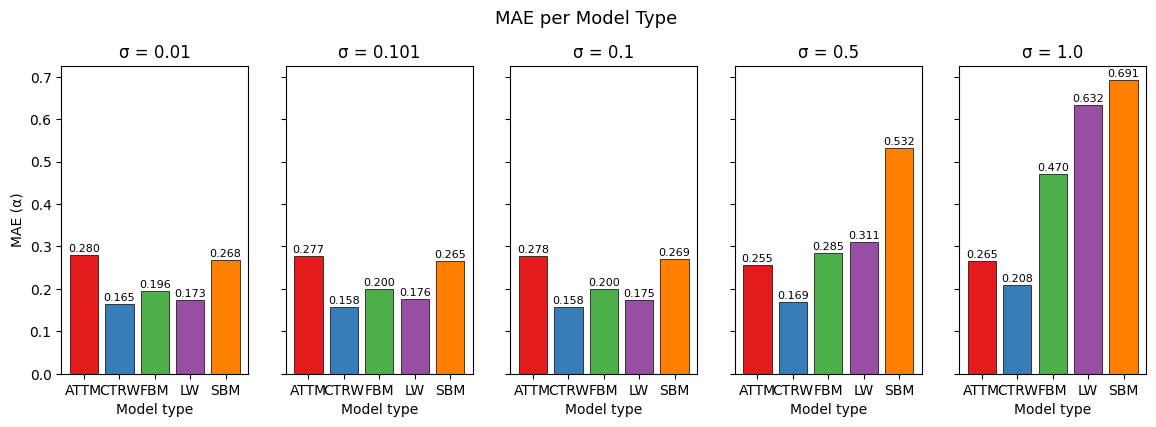

In [29]:
fig, axes = plt.subplots(1, len(NOISE_LEVELS), figsize=(14, 4), sharey=True)
fig.suptitle('MAE per Model Type', fontsize=13, y=1.02)

for ax, noise in zip(axes, NOISE_LEVELS):
    sub  = df[df['noise'] == noise]
    maes = [sub[sub['model'] == m]['ae'].mean() for m in MODEL_NAMES]
    bars = ax.bar(MODEL_NAMES, maes, color=MODEL_COLORS, edgecolor='k', linewidth=0.5)
    for bar, v in zip(bars, maes):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.003, f'{v:.3f}',
                ha='center', va='bottom', fontsize=8)
    ax.set_title(f'σ = {noise}')
    ax.set_xlabel('Model type')
    # ax.set_ylim(0, max(df['ae'].mean() * 2.2, 0.4))
    # ax.axhline(sub['ae'].mean(), color='gray', linestyle='--', linewidth=0.8, label='overall')

axes[0].set_ylabel('MAE (α)')


## 5. Plot 2 — MAE vs Trajectory Length

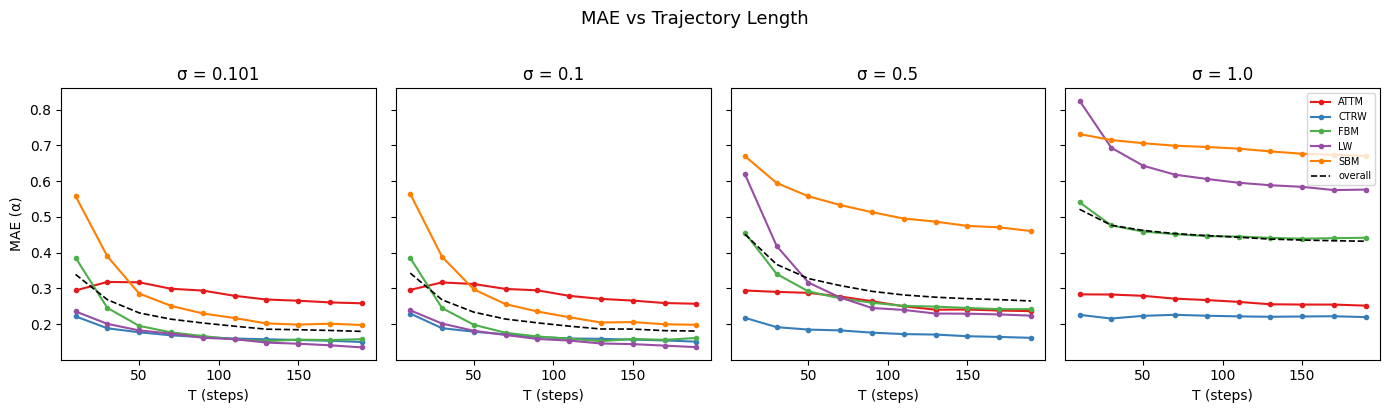

In [20]:
fig, axes = plt.subplots(1, len(NOISE_LEVELS), figsize=(14, 4), sharey=True)
fig.suptitle('MAE vs Trajectory Length', fontsize=13, y=1.02)

for ax, noise in zip(axes, NOISE_LEVELS):
    sub = df[df['noise'] == noise]
    for m, (name, color) in enumerate(zip(MODEL_NAMES, MODEL_COLORS)):
        grp  = sub[sub['model'] == name].groupby('T')['ae'].mean()
        ax.plot(grp.index, grp.values, marker='o', markersize=3,
                color=color, label=name, linewidth=1.5)
    overall = sub.groupby('T')['ae'].mean()
    ax.plot(overall.index, overall.values, 'k--', linewidth=1.2, label='overall')
    ax.set_title(f'σ = {noise}')
    ax.set_xlabel('T (steps)')
    # ax.set_xticks([10, 50, 100, 150, 200])

axes[0].set_ylabel('MAE (α)')
axes[-1].legend(loc='upper right', fontsize=7)
plt.tight_layout()
plt.show()

## 6. Plot 3 — MAE vs Noise Level

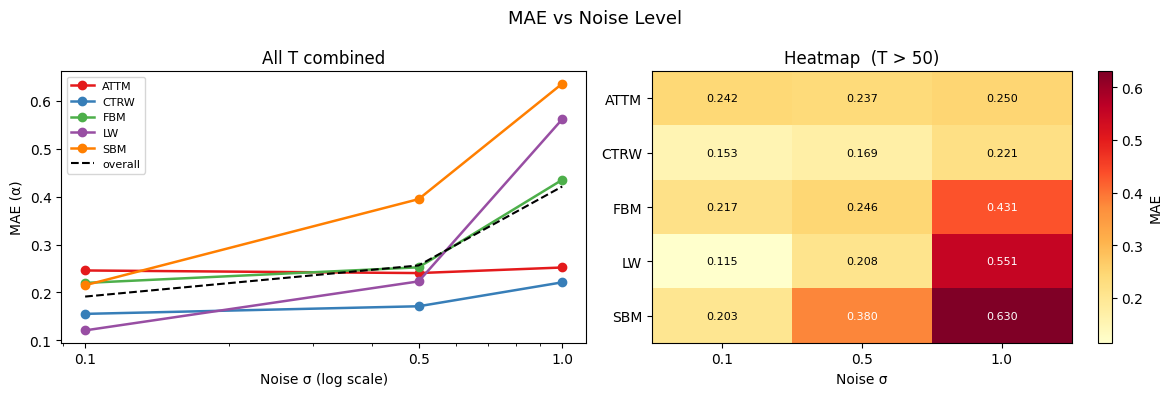

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('MAE vs Noise Level', fontsize=13)

# Left: one curve per model type, averaged over all T
ax = axes[0]
for name, color in zip(MODEL_NAMES, MODEL_COLORS):
    grp = df[df['model'] == name].groupby('noise')['ae'].mean()
    ax.plot(grp.index, grp.values, marker='o', color=color, label=name, linewidth=1.8)
overall = df.groupby('noise')['ae'].mean()
ax.plot(overall.index, overall.values, 'k--', linewidth=1.5, label='overall')
ax.set_xscale('log')
ax.set_xlabel('Noise σ (log scale)')
ax.set_ylabel('MAE (α)')
ax.set_title('All T combined')
ax.legend(fontsize=8)
ax.set_xticks(NOISE_LEVELS)
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())

# Right: heatmap — model × noise, averaged over T > 50 (mature trajectories)
ax = axes[1]
sub = df[df['T'] > 50].groupby(['model', 'noise'])['ae'].mean().unstack('noise')
sub = sub.reindex(MODEL_NAMES)
im  = ax.imshow(sub.values, aspect='auto', cmap='YlOrRd')
ax.set_xticks(range(len(NOISE_LEVELS)))
ax.set_xticklabels([str(n) for n in NOISE_LEVELS])
ax.set_yticks(range(len(MODEL_NAMES)))
ax.set_yticklabels(MODEL_NAMES)
ax.set_xlabel('Noise σ')
ax.set_title('Heatmap  (T > 50)')
plt.colorbar(im, ax=ax, label='MAE')
for i in range(len(MODEL_NAMES)):
    for j in range(len(NOISE_LEVELS)):
        ax.text(j, i, f'{sub.values[i, j]:.3f}', ha='center', va='center', fontsize=8,
                color='white' if sub.values[i, j] > sub.values.max() * 0.6 else 'black')

plt.tight_layout()
plt.show()

## 7. Summary Table

In [54]:
print('=== MAE by model × noise (all T) ===')
print(df.groupby(['model', 'noise'])['ae'].mean().unstack('noise')
        .reindex(MODEL_NAMES).round(4).to_string())

print('\n=== MAE by T-range × noise (all models) ===')
bins  = [0, 50, 100, 150, 200]
lbls  = ['10-50', '51-100', '101-150', '151-200']
df['T_bin'] = pd.cut(df['T'], bins=bins, labels=lbls)
print(df.groupby(['T_bin', 'noise'])['ae'].mean().unstack('noise').round(4).to_string())

=== MAE by model × noise (all T) ===
noise     0.1     0.5     1.0
model                        
ATTM   0.2458  0.2404  0.2520
CTRW   0.1553  0.1711  0.2211
FBM    0.2198  0.2524  0.4349
LW     0.1208  0.2231  0.5614
SBM    0.2150  0.3946  0.6355

=== MAE by T-range × noise (all models) ===
noise       0.1     0.5     1.0
T_bin                          
10-50    0.2767  0.3837  0.4910
51-100   0.2040  0.2975  0.4488
101-150  0.1867  0.2806  0.4368
151-200  0.1791  0.2697  0.4316


---
## 8. ANDI Challenge Predictions

Predicts **α (Task 1)** and **diffusion model (Task 2)** for the ANDI challenge files in `andi_trajs/`.

Preprocessing by input dimension:
- **2D** → fed directly as (T, 2) xy array
- **3D** → first two spatial dimensions extracted (`x` and `y`)
- **1D** → x-coordinate as column 0, y=0 as column 1 — the model still sees absolute displacements (dr) and directional reversals (dθ≈π) which carry diffusion information

The transformer backbone uses `pos_enc=False` so it generalises to trajectory lengths beyond T=200 without positional-encoding mismatch.

In [123]:
ANDI_DIR = Path('benchmark_data_andi1')
from andi_datasets.datasets_challenge import challenge_theory_dataset

MAX_CHALLENGE_TRAJS = 5000  # bug workaround: only keep first 5000 per task

def _flat_dim2_to_xy(traj_flat):
    """Convert ANDI dim=2 flattened trajectory [x(0..T-1), y(0..T-1)] to (T, 2)."""
    vals = np.asarray(traj_flat, dtype=np.float32)
    T = vals.size // 2
    return np.column_stack([vals[:T], vals[T:]])


def load_andi_file(path, max_trajs=MAX_CHALLENGE_TRAJS):
    """
    Load dim=2 trajectories for task 1/2 using challenge_theory_dataset.
    Keeps only the first `max_trajs` trajectories per task.

    Returns:
      trajs_t1: list[(dim, xy)] for Task 1
      ytrue_t1: np.ndarray of alpha labels (Task 1)
      trajs_t2: list[(dim, xy)] for Task 2
      ytrue_t2: np.ndarray of model labels (Task 2, ints 0..4)
    """
    # X1, Y1, X2, Y2, _, _ = challenge_theory_dataset(
    #     load_dataset=True,
    #     path_datasets=path,
    #     dimensions=[2],
    #     tasks=[1, 2],
    # )

    X1, Y1, X2, Y2, _, _ = challenge_theory_dataset(
        N = 5000, max_T = 200,
        load_dataset=False,
        path_datasets=path,
        dimensions=[2],
        tasks=[1, 2],
    )

    x1_dim2 = X1[1][:max_trajs]
    y1_dim2 = Y1[1][:max_trajs]
    x2_dim2 = X2[1][:max_trajs]
    y2_dim2 = Y2[1][:max_trajs]

    trajs_t1 = [(2, _flat_dim2_to_xy(traj)) for traj in x1_dim2]
    ytrue_t1 = np.asarray(y1_dim2, dtype=np.float32)

    trajs_t2 = [(2, _flat_dim2_to_xy(traj)) for traj in x2_dim2]
    ytrue_t2 = np.rint(np.asarray(y2_dim2, dtype=np.float32)).astype(np.int32)

    return trajs_t1, ytrue_t1, trajs_t2, ytrue_t2


print('Loading challenge trajectories via challenge_theory_dataset...')
trajs_t1, ytrue_t1, trajs_t2, ytrue_t2 = load_andi_file(ANDI_DIR)

print(f'Task 1 (dim=2): {len(trajs_t1)} trajectories (capped at {MAX_CHALLENGE_TRAJS})')
print(f'Task 2 (dim=2): {len(trajs_t2)} trajectories (capped at {MAX_CHALLENGE_TRAJS})')
print(f'Task 2 true class counts: { {MODEL_NAMES[i]: int((ytrue_t2 == i).sum()) for i in range(5)} }')

lens_t1 = np.array([xy.shape[0] for _, xy in trajs_t1])
lens_t2 = np.array([xy.shape[0] for _, xy in trajs_t2])
print(f'Task 1 T: min={lens_t1.min()}, median={int(np.median(lens_t1))}, max={lens_t1.max()}')
print(f'Task 2 T: min={lens_t2.min()}, median={int(np.median(lens_t2))}, max={lens_t2.max()}')

Loading challenge trajectories via challenge_theory_dataset...
Creating a dataset for task(s) [1, 2] and dimension(s) [2].
Generating dataset for dimension 2.
Task 1 (dim=2): 5000 trajectories (capped at 5000)
Task 2 (dim=2): 5000 trajectories (capped at 5000)
Task 2 true class counts: {'ATTM': 1004, 'CTRW': 1003, 'FBM': 988, 'LW': 992, 'SBM': 1013}
Task 1 T: min=10, median=103, max=199
Task 2 T: min=10, median=104, max=199


In [124]:
def infer_challenge(trajs, desc='Inference'):
    """
    Run V2-Exp14 on a list of (dim, xy) pairs with variable trajectory length.

    Returns:
      alphas    : (N,) float  — soft-routed alpha (output col 10)
      cls_preds : (N,) int    — argmax model class (cols 5-9)
      cls_probs : (N, 5) float — softmax probabilities per class
    """
    N = len(trajs)
    alphas    = np.zeros(N,      dtype=np.float32)
    cls_preds = np.zeros(N,      dtype=np.int32)
    cls_probs = np.zeros((N, 5), dtype=np.float32)

    # Group by T to enable batched forward passes
    by_len = defaultdict(list)
    for i, (_, xy) in enumerate(trajs):
        by_len[xy.shape[0]].append(i)

    model.eval()
    with torch.no_grad():
        for T_val, idxs in tqdm(sorted(by_len.items()), desc=desc):
            xys = np.stack([trajs[i][1] for i in idxs])           # (B, T, 2)
            xys_t = torch.tensor(xys) + torch.randn(len(idxs), T_val, 2) * 0.001
            polars = torch.tensor(
                cartesian_to_relative_polar(xys_t.numpy()), dtype=torch.float32
            )  # (B, T-1, 2)

            # Use smaller batches for very long trajectories to avoid OOM
            bs = max(1, 64 // max(1, T_val // 200))
            for start in range(0, len(idxs), bs):
                batch_i = idxs[start:start + bs]
                out = model(polars[start:start + bs].to(dvc))   # (b, 11)
                out_cpu = out.cpu()
                for j, idx in enumerate(batch_i):
                    alphas[idx]    = float(out_cpu[j, 10])
                    probs          = F.softmax(out_cpu[j, 5:10], dim=0).numpy()
                    cls_probs[idx] = probs
                    cls_preds[idx] = int(probs.argmax())

    return alphas, cls_preds, cls_probs


print('Running inference on Task 1 trajectories...')
alphas_t1, cls_t1, probs_t1 = infer_challenge(trajs_t1, desc='Task 1')

print('\nRunning inference on Task 2 trajectories...')
alphas_t2, cls_t2, probs_t2 = infer_challenge(trajs_t2, desc='Task 2')

print(f'\nTask 1 alpha: mean={alphas_t1.mean():.3f}, std={alphas_t1.std():.3f}')
print(f'Task 2 predicted class counts: { {MODEL_NAMES[i]: int((cls_t2==i).sum()) for i in range(5)} }')

# Build separate records/dataframes for each task.
records_task1 = []
for (dim, xy), alpha_true, alpha_pred, cls_pred in zip(trajs_t1, ytrue_t1, alphas_t1, cls_t1):
    records_task1.append({
        'task': 1,
        'dim': int(dim),
        'T': int(xy.shape[0]),
        'alpha_true': float(alpha_true),
        'alpha_pred': float(alpha_pred),
        'ae': abs(float(alpha_true) - float(alpha_pred)),
        'model_pred': int(cls_pred),
        'model_pred_name': MODEL_NAMES[int(cls_pred)],
    })

records_task2 = []
for (dim, xy), model_true, alpha_pred, cls_pred in zip(trajs_t2, ytrue_t2, alphas_t2, cls_t2):
    records_task2.append({
        'task': 2,
        'dim': int(dim),
        'T': int(xy.shape[0]),
        'model_true': int(model_true),
        'model_true_name': MODEL_NAMES[int(model_true)],
        'model_pred': int(cls_pred),
        'model_pred_name': MODEL_NAMES[int(cls_pred)],
        'cls_correct': bool(int(model_true) == int(cls_pred)),
        'alpha_pred': float(alpha_pred),
    })

df_task1 = pd.DataFrame(records_task1)
df_task2 = pd.DataFrame(records_task2)

print(f'\ndf_task1 shape: {df_task1.shape}')
display(df_task1.head())

print(f'\ndf_task2 shape: {df_task2.shape}')
display(df_task2.head())

df_task1.ae.mean(), df_task2.cls_correct.mean()

Running inference on Task 1 trajectories...


Task 1:   0%|          | 0/190 [00:00<?, ?it/s]


Running inference on Task 2 trajectories...


Task 2:   0%|          | 0/190 [00:00<?, ?it/s]


Task 1 alpha: mean=0.775, std=0.410
Task 2 predicted class counts: {'ATTM': 915, 'CTRW': 988, 'FBM': 1786, 'LW': 487, 'SBM': 824}

df_task1 shape: (5000, 8)


,task,dim,T,alpha_true,alpha_pred,ae,model_pred,model_pred_name
0,1,2,135,0.55,0.562189,0.012189,1,CTRW
1,1,2,78,1.10,1.189791,0.089791,3,LW
2,1,2,26,0.55,0.482262,0.067738,1,CTRW
3,1,2,189,0.25,0.484046,0.234046,1,CTRW
4,1,2,95,0.90,0.558123,0.341877,4,SBM



df_task2 shape: (5000, 9)


,task,dim,T,model_true,model_true_name,model_pred,model_pred_name,cls_correct,alpha_pred
0,2,2,185,3,LW,3,LW,True,1.564110
1,2,2,89,0,ATTM,2,FBM,False,0.468724
2,2,2,128,2,FBM,0,ATTM,False,0.742416
3,2,2,183,0,ATTM,2,FBM,False,0.571963
4,2,2,181,3,LW,3,LW,True,1.198395


(0.3618022200651467, 0.6236)

In [114]:
df_task1.head()

,task,dim,T,alpha_true,alpha_pred,ae,model_pred,model_pred_name
0,1,2,900,1.40,0.724830,0.675170,2,FBM
1,1,2,152,1.15,0.705676,0.444324,2,FBM
2,1,2,332,0.40,0.245728,0.154272,2,FBM
3,1,2,440,0.70,0.602881,0.097119,0,ATTM
4,1,2,39,1.15,0.309017,0.840983,2,FBM


In [113]:
df_task2.head()

,task,dim,T,model_true,model_true_name,model_pred,model_pred_name,cls_correct,alpha_pred
0,2,2,603,1,CTRW,0,ATTM,False,0.347523
1,2,2,531,4,SBM,2,FBM,False,0.565897
2,2,2,198,2,FBM,2,FBM,True,0.768413
3,2,2,935,0,ATTM,2,FBM,False,0.495574
4,2,2,276,3,LW,3,LW,True,1.679035


In [ ]:
df_task1.

In [115]:
df_task1.ae.mean(), df_task2.cls_correct.mean()

(0.385670214124769, 0.5718)

In [11]:
# ── Save predictions ─────────────────────────────────────────────────────────
# Submission format:  dim;value   (one line per trajectory, matching input order)
# Task 1: alpha as float with 5 decimal places
# Task 2: model index as integer (0=ATTM, 1=CTRW, 2=FBM, 3=LW, 4=SBM)

out_t1 = ANDI_DIR / 'task1_pred.txt'
out_t2 = ANDI_DIR / 'task2_pred.txt'

with open(out_t1, 'w') as f:
    for (dim, _), alpha in zip(trajs_t1, alphas_t1):
        f.write(f'{dim:.1f};{alpha:.5f}\n')

with open(out_t2, 'w') as f:
    for (dim, _), cls in zip(trajs_t2, cls_t2):
        f.write(f'{dim:.1f};{int(cls)}\n')

print(f'Saved {len(alphas_t1)} predictions → {out_t1}')
print(f'Saved {len(cls_t2)} predictions    → {out_t2}')

# Preview first 5 lines of each
print('\nTask 1 preview:')
with open(out_t1) as f:
    print(''.join(f.readlines()[:5]))
print('Task 2 preview:')
with open(out_t2) as f:
    print(''.join(f.readlines()[:5]))

Saved 39927 predictions → benchmark_data_andi1/task1_pred.txt
Saved 39927 predictions    → benchmark_data_andi1/task2_pred.txt

Task 1 preview:
1.0;1.83291
1.0;0.43626
1.0;0.56779
1.0;0.70098
1.0;0.52135

Task 2 preview:
1.0;0
1.0;2
1.0;0
1.0;2
1.0;0



/home/gorka/miniconda3/envs/kistep/lib/python3.11/site-packages/numpy/lib/histograms.py:885: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges
/home/gorka/miniconda3/envs/kistep/lib/python3.11/site-packages/numpy/lib/histograms.py:885: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


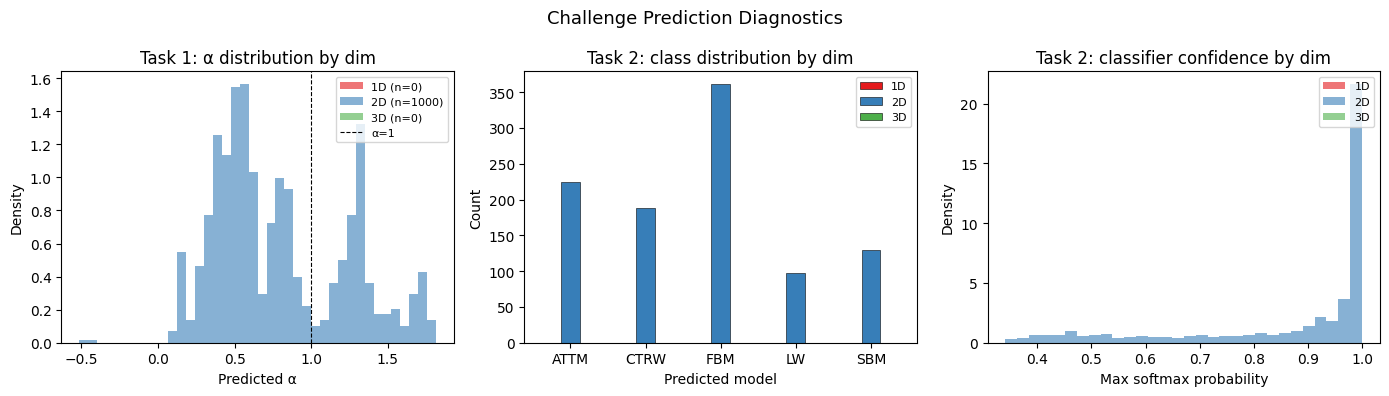

1D  conf: mean=nan  >0.9: nan%
2D  conf: mean=0.865  >0.9: 65.8%
3D  conf: mean=nan  >0.9: nan%


/tmp/ipykernel_100323/3093654042.py:55: RuntimeWarning: Mean of empty slice.
  print(f'{d}D  conf: mean={conf[mask].mean():.3f}  >0.9: {(conf[mask]>0.9).mean():.1%}')
/home/gorka/miniconda3/envs/kistep/lib/python3.11/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)
/home/gorka/miniconda3/envs/kistep/lib/python3.11/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [121]:
# ── Sanity-check plots ────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle('Challenge Prediction Diagnostics', fontsize=13)

dims_t1 = np.array([d for d, _ in trajs_t1])
dims_t2 = np.array([d for d, _ in trajs_t2])
dim_colors = {1: '#e41a1c', 2: '#377eb8', 3: '#4daf4a'}

# Task 1: predicted α distribution split by input dimension
ax = axes[0]
for d in [1, 2, 3]:
    mask = dims_t1 == d
    ax.hist(alphas_t1[mask], bins=40, alpha=0.6, color=dim_colors[d],
            label=f'{d}D (n={mask.sum()})', density=True)
ax.axvline(1.0, color='k', linestyle='--', linewidth=0.8, label='α=1')
ax.set_xlabel('Predicted α')
ax.set_ylabel('Density')
ax.set_title('Task 1: α distribution by dim')
ax.legend(fontsize=8)

# Task 2: class predictions split by dimension
ax = axes[1]
x = np.arange(5)
w = 0.25
for k, d in enumerate([1, 2, 3]):
    mask  = dims_t2 == d
    cnts  = np.array([int((cls_t2[mask] == i).sum()) for i in range(5)])
    ax.bar(x + (k - 1) * w, cnts, w, label=f'{d}D', color=dim_colors[d],
           edgecolor='k', linewidth=0.4)
ax.set_xticks(x)
ax.set_xticklabels(MODEL_NAMES)
ax.set_xlabel('Predicted model')
ax.set_ylabel('Count')
ax.set_title('Task 2: class distribution by dim')
ax.legend(fontsize=8)

# Task 2: classifier confidence
ax = axes[2]
conf = probs_t2.max(axis=1)
for d in [1, 2, 3]:
    mask = dims_t2 == d
    ax.hist(conf[mask], bins=30, alpha=0.6, color=dim_colors[d],
            label=f'{d}D', density=True)
ax.set_xlabel('Max softmax probability')
ax.set_ylabel('Density')
ax.set_title('Task 2: classifier confidence by dim')
ax.legend(fontsize=8)

plt.tight_layout()
# plt.savefig('challenge_predictions_summary.png', dpi=150, bbox_inches='tight')
plt.show()

for d in [1, 2, 3]:
    mask = dims_t2 == d
    print(f'{d}D  conf: mean={conf[mask].mean():.3f}  >0.9: {(conf[mask]>0.9).mean():.1%}')

# With Model V3-Exp1

Inherited from V2-Exp18 but now trained on same noise as andi

In [24]:
# ── Experiment config ────────────────────────────────────────────────────────
T_MAX        = 1000
T_VALUES     = list(range(10, 201, 20))          # 10, 20, ..., 200  (20 values)
NOISE_LEVELS = [0.1, 0.5, 1.0]
N_PER_GROUP  = 500                               # trajectories per (model, T, noise)
MODEL_NAMES  = ['ATTM', 'CTRW', 'FBM', 'LW', 'SBM']
MODEL_COLORS = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3', '#ff7f00']
CACHE_PATH   = Path('eval_v3_noise_sweep.pkl')
MODEL_PATH   = Path('models/V3-Exp1_model.pth')

## 1. Model Architecture

In [4]:
# Same as previous V2-Exp14

## 2. Load Model

In [18]:
backbone = XResAttn(
    2, n_class=1, stem_szs=(32,), conv_blocks=[1, 1, 1],
    block_szs=[128, 256, 512], dropout=0., pos_enc=False,
    n_encoder_layers=4, dim_ff=512, nhead_enc=8, norm=False, linear_layers=[]
)
model = V2CombinedModel(backbone, n_models=5, dropout=0.1).to(dvc)
model.load_state_dict(torch.load(MODEL_PATH, map_location=dvc))
model.eval()
print(f'Loaded {MODEL_PATH}')
total = sum(p.numel() for p in model.parameters())
print(f'Parameters: {total:,}')

Loaded models/V3-Exp1_model.pth
Parameters: 11,924,258


## 3. Generate Dataset

Generates trajectories at T_max=200 once per noise level, then cuts to each T.  
Result is cached to `eval_v3_noise_sweep.pkl` — delete the file to regenerate.

In [ ]:
def generate_base_dataset(n_per_group, noise_levels):
    """Generate clean trajectories at T_max=200 covering all 5 model types."""
    n_total     = n_per_group  # per model type — same trajectories reused across noise levels
    exponents   = np.linspace(0.1, 1.9, 10)
    n_exp       = len(exponents)
    subdif      = 5  # exponents[:5] < 1, exponents[5:] > 1
    n_per_exp   = int(np.ceil(n_total / n_exp))

    n_per_class = np.zeros((5, n_exp))
    n_per_class[0, :subdif] = int(np.ceil(n_total / subdif))  # ATTM: subdiff
    n_per_class[1, :subdif] = int(np.ceil(n_total / subdif))  # CTRW: subdiff
    n_per_class[2, :]       = n_per_exp                        # FBM: all α
    n_per_class[3, subdif:] = int(np.ceil(n_total / subdif))  # LW: superdiff
    n_per_class[4, :]       = n_per_exp                        # SBM: all α

    print(f'Generating base trajectories (T={T_MAX}, no noise)...')
    dt = datasets_theory()
    dataset = dt.create_dataset(
        T=T_MAX, N_models=n_per_class, exponents=exponents,
        dimension=2, models=np.arange(5),
        load_trajectories=False, save_trajectories=False,
        N_save=100, path='datasets/'
    )

    n_traj = dataset.shape[0]
    norm_trajs = normalize(dataset[:, 2:].reshape(n_traj * 2, T_MAX))
    dataset[:, 2:] = norm_trajs.reshape(dataset[:, 2:].shape)
    print(f'  Base dataset: {n_traj} trajectories')
    return dataset, dt


def raw_to_polar(raw, T):
    """raw: (2*T,) array -> polar tensor (T-1, 2)"""
    xy = torch.tensor(raw, dtype=torch.float32).reshape(2, T).T.unsqueeze(0)  # (1,T,2)
    xy = xy + torch.randn_like(xy) * 0.001  # tiny jitter to avoid zero-displacement
    return torch.tensor(
        cartesian_to_relative_polar(xy.numpy()), dtype=torch.float32
    ).squeeze(0)  # (T-1, 2)


def run_inference_batch(model, polar_list, batch_size=256):
    """All tensors in polar_list have the same shape (T-1, 2). Returns alpha + class predictions."""
    n = len(polar_list)
    preds = np.zeros(n, dtype=np.float32)
    cls_preds = np.zeros(n, dtype=np.int32)
    cls_probs = np.zeros((n, 5), dtype=np.float32)

    with torch.no_grad():
        for i in range(0, n, batch_size):
            batch = torch.stack(polar_list[i:i + batch_size]).to(dvc)
            out = model(batch)
            out_cpu = out.cpu()
            for j in range(out_cpu.shape[0]):
                idx = i + j
                preds[idx] = float(out_cpu[j, 10])
                probs = F.softmax(out_cpu[j, 5:10], dim=0).numpy()
                cls_probs[idx] = probs
                cls_preds[idx] = int(probs.argmax())

    return preds, cls_preds, cls_probs


if CACHE_PATH.exists():
    print(f'Loading cached results from {CACHE_PATH}')
    with open(CACHE_PATH, 'rb') as f:
        records = pickle.load(f)
    print(f'  {len(records)} records loaded')
else:
    dataset_base, dt = generate_base_dataset(N_PER_GROUP, NOISE_LEVELS)
    records = []  # list of dicts: model, T, noise, alpha_true, alpha_pred, model_pred, model_correct

    for noise_idx, noise in enumerate(tqdm(NOISE_LEVELS, desc='Noise levels')):
        # Apply localization noise to base trajectories
        n_traj  = dataset_base.shape[0]
        noise_amp = np.full(n_traj * 2, noise)
        loc_err   = (np.random.randn(n_traj * 2, T_MAX).T * noise_amp).T
        noisy     = dt.create_noisy_localization_dataset(
            dataset_base.copy(), dimension=2, T=T_MAX, noise_func=loc_err
        )

        for T in tqdm(T_VALUES, desc=f'  σ={noise}  T', leave=False):
            for m in range(5):
                rows = noisy[noisy[:, 0] == m]
                # All noise levels use the same N_PER_GROUP trajectories
                sample = rows[:N_PER_GROUP]
                if len(sample) == 0:
                    continue

                polars, alphas = [], []
                for row in sample:
                    traj_cut = dt._cut_trajectory(row[2:], T, dim=2)
                    polars.append(raw_to_polar(np.array(traj_cut, dtype=np.float32), T))
                    alphas.append(float(row[1]))

                preds, cls_preds, cls_probs = run_inference_batch(model, polars)
                for alpha_true, alpha_pred, model_pred in zip(alphas, preds, cls_preds):
                    records.append({
                        'model':      MODEL_NAMES[m],
                        'T':          T,
                        'noise':      noise,
                        'alpha_true': alpha_true,
                        'alpha_pred': float(alpha_pred),
                        'ae':         abs(alpha_true - float(alpha_pred)),
                        'model_pred': int(model_pred),
                        'model_correct': int(int(model_pred) == m),
                    })

    # print(f'\nSaving {len(records)} records to {CACHE_PATH}')
    # with open(CACHE_PATH, 'wb') as f:
    #     pickle.dump(records, f)

df = pd.DataFrame(records)
print(df.groupby(['model', 'noise'])['ae'].mean().unstack('noise').round(3))


Generating base trajectories (T=1000, no noise)...
  Base dataset: 2500 trajectories


Noise levels:   0%|          | 0/3 [00:00<?, ?it/s]

  σ=0.1  T:   0%|          | 0/10 [00:00<?, ?it/s]

  σ=0.5  T:   0%|          | 0/10 [00:00<?, ?it/s]

  σ=1.0  T:   0%|          | 0/10 [00:00<?, ?it/s]

noise    0.1    0.5    1.0
model                     
ATTM   0.322  0.303  0.268
CTRW   0.176  0.178  0.186
FBM    0.188  0.219  0.341
LW     0.175  0.217  0.365
SBM    0.283  0.451  0.610


In [26]:
df.ae.values.mean()

0.28562638042712213

## 4. Plot 1 — MAE per Model Type

Text(0, 0.5, 'MAE (α)')

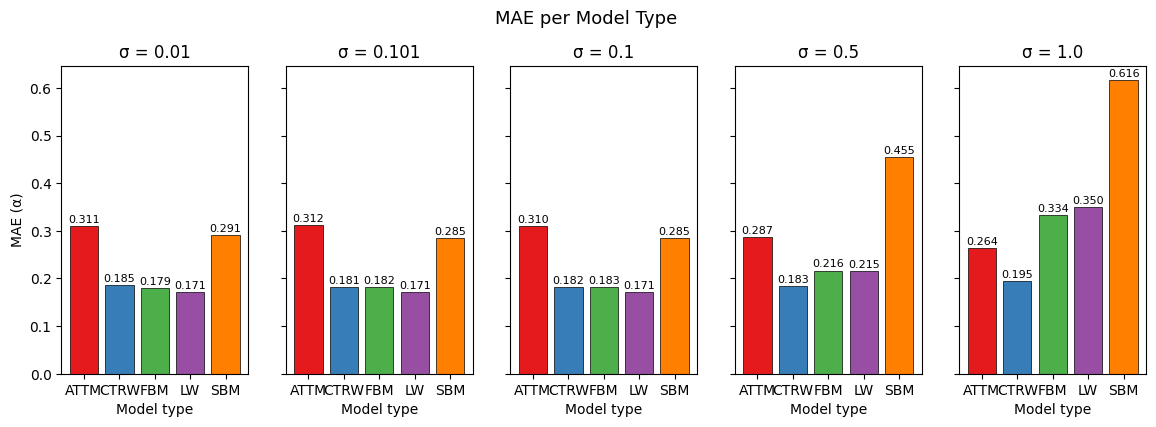

In [23]:
fig, axes = plt.subplots(1, len(NOISE_LEVELS), figsize=(14, 4), sharey=True)
fig.suptitle('MAE per Model Type', fontsize=13, y=1.02)

for ax, noise in zip(axes, NOISE_LEVELS):
    sub  = df[df['noise'] == noise]
    maes = [sub[sub['model'] == m]['ae'].mean() for m in MODEL_NAMES]
    bars = ax.bar(MODEL_NAMES, maes, color=MODEL_COLORS, edgecolor='k', linewidth=0.5)
    for bar, v in zip(bars, maes):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.003, f'{v:.3f}',
                ha='center', va='bottom', fontsize=8)
    ax.set_title(f'σ = {noise}')
    ax.set_xlabel('Model type')
    # ax.set_ylim(0, max(df['ae'].mean() * 2.2, 0.4))
    # ax.axhline(sub['ae'].mean(), color='gray', linestyle='--', linewidth=0.8, label='overall')

axes[0].set_ylabel('MAE (α)')


## 5. Plot 2 — MAE vs Trajectory Length

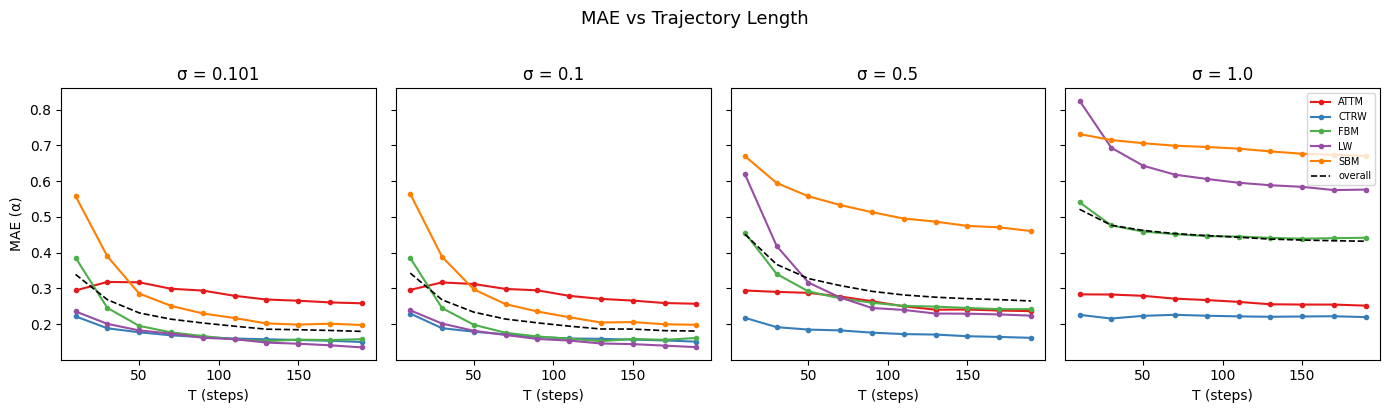

In [ ]:
fig, axes = plt.subplots(1, len(NOISE_LEVELS), figsize=(14, 4), sharey=True)
fig.suptitle('MAE vs Trajectory Length', fontsize=13, y=1.02)

for ax, noise in zip(axes, NOISE_LEVELS):
    sub = df[df['noise'] == noise]
    for m, (name, color) in enumerate(zip(MODEL_NAMES, MODEL_COLORS)):
        grp  = sub[sub['model'] == name].groupby('T')['ae'].mean()
        ax.plot(grp.index, grp.values, marker='o', markersize=3,
                color=color, label=name, linewidth=1.5)
    overall = sub.groupby('T')['ae'].mean()
    ax.plot(overall.index, overall.values, 'k--', linewidth=1.2, label='overall')
    ax.set_title(f'σ = {noise}')
    ax.set_xlabel('T (steps)')
    # ax.set_xticks([10, 50, 100, 150, 200])

axes[0].set_ylabel('MAE (α)')
axes[-1].legend(loc='upper right', fontsize=7)
plt.tight_layout()
plt.show()

## 6. Plot 3 — MAE vs Noise Level

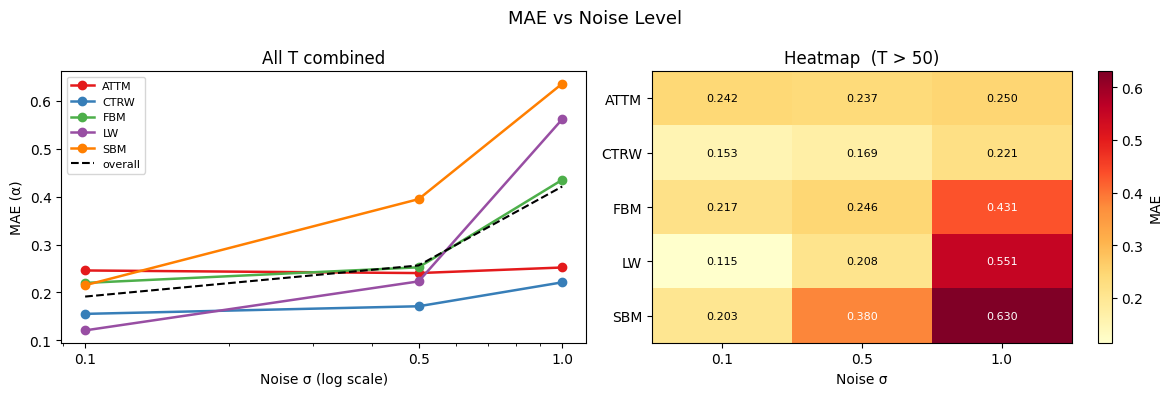

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('MAE vs Noise Level', fontsize=13)

# Left: one curve per model type, averaged over all T
ax = axes[0]
for name, color in zip(MODEL_NAMES, MODEL_COLORS):
    grp = df[df['model'] == name].groupby('noise')['ae'].mean()
    ax.plot(grp.index, grp.values, marker='o', color=color, label=name, linewidth=1.8)
overall = df.groupby('noise')['ae'].mean()
ax.plot(overall.index, overall.values, 'k--', linewidth=1.5, label='overall')
ax.set_xscale('log')
ax.set_xlabel('Noise σ (log scale)')
ax.set_ylabel('MAE (α)')
ax.set_title('All T combined')
ax.legend(fontsize=8)
ax.set_xticks(NOISE_LEVELS)
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())

# Right: heatmap — model × noise, averaged over T > 50 (mature trajectories)
ax = axes[1]
sub = df[df['T'] > 50].groupby(['model', 'noise'])['ae'].mean().unstack('noise')
sub = sub.reindex(MODEL_NAMES)
im  = ax.imshow(sub.values, aspect='auto', cmap='YlOrRd')
ax.set_xticks(range(len(NOISE_LEVELS)))
ax.set_xticklabels([str(n) for n in NOISE_LEVELS])
ax.set_yticks(range(len(MODEL_NAMES)))
ax.set_yticklabels(MODEL_NAMES)
ax.set_xlabel('Noise σ')
ax.set_title('Heatmap  (T > 50)')
plt.colorbar(im, ax=ax, label='MAE')
for i in range(len(MODEL_NAMES)):
    for j in range(len(NOISE_LEVELS)):
        ax.text(j, i, f'{sub.values[i, j]:.3f}', ha='center', va='center', fontsize=8,
                color='white' if sub.values[i, j] > sub.values.max() * 0.6 else 'black')

plt.tight_layout()
plt.show()